# 03 · Signatures — embryonic-development module scores & Gate 2

The three embryonic modules (Gastrulation, Somitogenesis, Neural Crest) are scored on the manifold
(in 02) and mapped here. **Gate 2** tests whether the module geography reproduces: for this dataset
Gast and pSom **co-vary** along a single axis with Crest as the **inverse terminal** gradient — the
non-branching case, which passes (GO) with no bifurcation for Gate 3 (NA).

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import warnings; warnings.filterwarnings('ignore')
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the rooted manifold (signatures scored + smoothed in 02)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present | raw mean {adata.obs[lab].mean():+.3f}')

Gast: 71/81 genes present | raw mean +0.010
pSom: 86/98 genes present | raw mean +0.099
Crest: 100/104 genes present | raw mean +0.041


### Gate 2 — module geography on the manifold
Quantitative test of the non-branching signature: Gast/pSom share a gradient (positive spatial
correlation, both rising toward the root) while Crest runs inverse and peaks terminally. Read on the
graph-smoothed scores; the deliverable UMAPs below show the raw scores.

In [ ]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a], adata.obs[b])[0,1]:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
print('global module means (raw):', {m: round(float(adata.obs[m].mean()),3) for m in modules})
print('Gate 2: shared Gast/pSom gradient + inverse terminal Crest -> GO (non-branching).')
print('Gate 3: no bifurcation -> NA. Crest-arm flag: none (no arms; Crest is the terminal pole).')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = +0.72
  Crest_sm vs Gast_sm: r = -0.92
  Crest_sm vs pSom_sm: r = -0.59
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.608
  pSom_sm: rho = -0.145
  Crest_sm: rho = +0.807
Neural-crest-high decile mean pseudotime = 0.98 (terminal if ~1)
global module means (raw): {'Gast': 0.01, 'pSom': 0.099, 'Crest': 0.041}
Gate 2: shared Gast/pSom gradient + inverse terminal Crest -> GO (non-branching).
Gate 3: no bifurcation -> NA. Crest-arm flag: none (no arms; Crest is the terminal pole).


### Module maps — overview (house linear layout, pseudotime left → right)

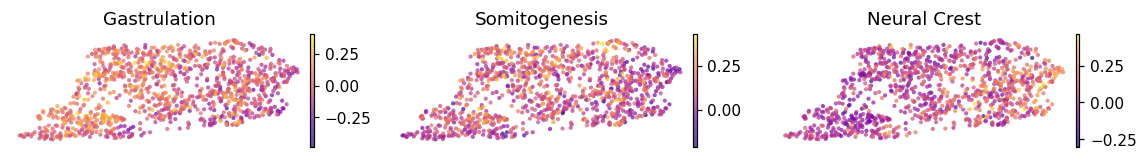

In [ ]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, axes = plt.subplots(1, 3, figsize=(10.5,1.6))
for ax,(m,title) in zip(axes, modules.items()):
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=title)
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
fig.tight_layout()

### Per-module signature figures + colorbars (deliverable)
House style: `figsize=(3.5,1.5)`, `size=30`, **raw** per-cell scores (smoothing aids the analysis but
misleads as a deliverable — 04_test Chen attempt 7), one external colorbar per module.

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


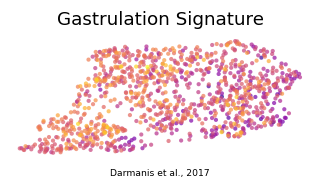

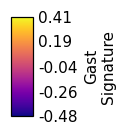

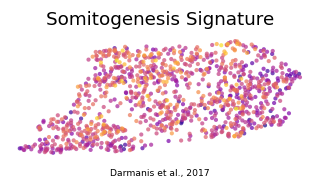

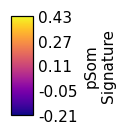

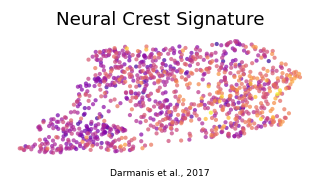

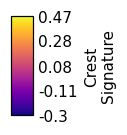

In [ ]:
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Darmanis et al., 2017', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

### Save signatures data

In [ ]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (1091, 18682)
